# HMM-style Viterbi route reconstruction

This notebook explains the code in pathsnap.py and compares **classifier-only** arc choices with **classifier plus Viterbi** choices. It uses the saved final tuned HGB model and the same 10 student-test trips. Saved outputs come from a real run. The separate reserved evaluator set is not used.

Our decoder is **HMM-style**: it uses hidden road-arc states, model-based emission scores, heuristic transition penalties, and Viterbi dynamic programming. It does **not** fit a fully normalized HMM transition matrix. This wording matters in a viva.

## 1. Hidden states, observations, and emissions

At GPS time t, the hidden state is **one of six candidate directed road arcs** near that observation. It is called hidden because the GPS receiver tells us longitude, latitude, and time, but not the exact road arc. These are **hidden states, not neural-network hidden layers**. HGB and this decoder have no neural layers.

For each GPS point–candidate arc pair, HGB sees six engineered features: point-to-arc distance, movement-versus-road direction cosine, speed, road-segment length, time gap, and movement length. HGB predict_proba gives the candidate positive-class score. The decoder clips it to [1e-6, 1] and uses its log as the **emission score**. It is a classifier score, not a separately estimated generative GPS-noise distribution.

In [1]:
import os
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from matplotlib.collections import LineCollection
from train import collect
from pathsnap import decode, route_continuity

DATA_ROOT = Path(os.environ.get("PATHSNAP_DATA_ROOT", "data"))
assert (DATA_ROOT / "student_test").is_dir(), DATA_ROOT
model = joblib.load("artifacts/final_model.joblib")
with redirect_stdout(StringIO()):
    _, _, _, trips = collect(DATA_ROOT / "student_test", 250)
print(type(model).__name__, "| student-test trips:", len(trips))
print("Candidate states per observation:", trips[0]["candidates"].shape[1])

C:\Users\athar\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HistGradientBoostingClassifier | student-test trips: 10
Candidate states per observation: 6


## 2. Transition scores and Viterbi recursion

For the previous arc i and current arc j, the code uses a **penalty**:

| Relationship | Penalty |
|---|---:|
| Same arc | 0 |
| Previous arc ends where next arc starts | 0.25 |
| Otherwise disconnected | 1.5 + endpoint_gap_metres / (25 × elapsed_seconds) |

The transition score is **negative penalty times transition_weight** (default 1.0). These are *unnormalized heuristic scores*, not a learned transition-probability matrix. Viterbi keeps, for each current candidate, the best preceding candidate and cumulative score: previous score + log emission − transition penalty. Backtracking from the best final state recovers one arc per GPS observation.

A larger GPS time gap reduces the distance part of the disconnected penalty, so the decoder can recover after missing samples. If the correct road is absent from all six candidates, decoding cannot select it at that observation. For disconnected decoded arcs, bridge_route later attempts a directed A* road-graph bridge; it rejects implausibly long bridges and reports unresolved links.

,GPS sample,Classifier-only proxy accuracy (%),After-Viterbi proxy accuracy (%),Accuracy change (pp),Continuity before (%),Continuity after (%),Continuity change (pp),Candidate miss (%)
trip,,,,,,,,
00000000,250.00,89.60,92.00,2.40,76.31,81.12,4.82,2.80
00000007,250.00,90.80,91.60,0.80,89.16,92.37,3.21,0.40
00000009,250.00,68.40,66.00,-2.40,40.16,61.85,21.69,1.60
00000040,250.00,84.80,87.20,2.40,61.04,71.08,10.04,0.40
00000052,250.00,83.20,85.20,2.00,86.35,93.98,7.63,2.80
00000056,250.00,72.40,68.40,-4.00,10.04,17.27,7.23,1.20
00000065,250.00,63.60,66.80,3.20,70.28,85.94,15.66,5.20
00000076,250.00,71.60,71.60,0.00,44.58,60.64,16.06,2.00
00000077,250.00,58.00,60.80,2.80,57.03,71.08,14.06,0.80


Mean per-trip proxy accuracy: 75.40% → 76.72%
Mean per-trip route continuity: 60.36% → 71.97%


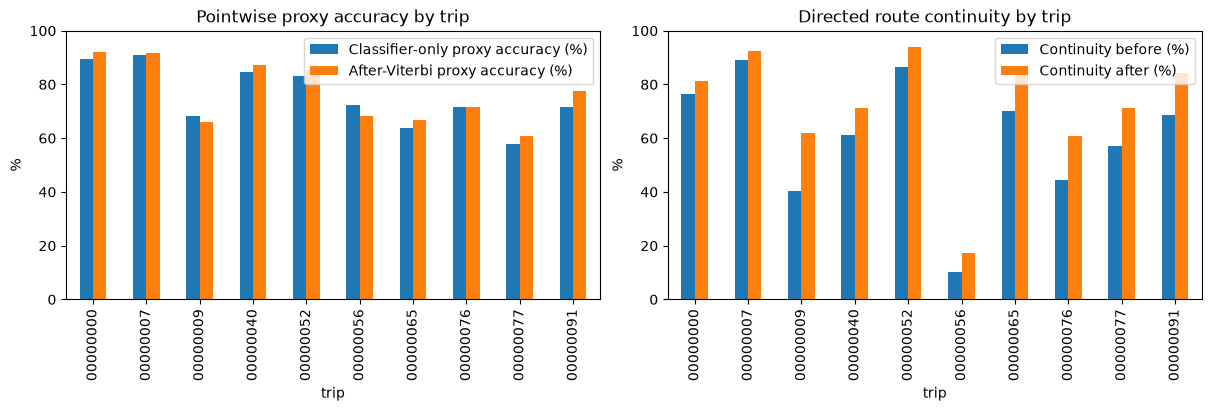

In [2]:
rows = []
decoded_by_trip = {}
for item in trips:
    trip, road, ids, candidates, features = (item[k] for k in
        ("trip", "road", "point_ids", "candidates", "features"))
    scores = model.predict_proba(features.reshape(-1, features.shape[-1]))[:, 1].reshape(candidates.shape)
    classifier = candidates[np.arange(len(ids)), np.argmax(scores, axis=1)]
    decoded = decode(trip, road, ids, candidates, scores)
    truth_proxy = road.reference_arc_per_point(road.track_xy[ids])
    before = float(np.mean(classifier == truth_proxy))
    after = float(np.mean(decoded == truth_proxy))
    cb = route_continuity(trip, classifier)
    ca = route_continuity(trip, decoded)
    rows.append({"trip": trip.trip_id, "GPS sample": len(ids),
        "Classifier-only proxy accuracy (%)": 100*before,
        "After-Viterbi proxy accuracy (%)": 100*after,
        "Accuracy change (pp)": 100*(after-before),
        "Continuity before (%)": 100*cb,
        "Continuity after (%)": 100*ca,
        "Continuity change (pp)": 100*(ca-cb),
        "Candidate miss (%)": 100*(1-item["labels"].any(axis=1).mean())})
    decoded_by_trip[trip.trip_id] = (item, classifier, decoded)
per_trip = pd.DataFrame(rows).set_index("trip")
display(per_trip.style.format("{:.2f}"))
mean_row = per_trip.mean(numeric_only=True)
print(f"Mean per-trip proxy accuracy: {mean_row['Classifier-only proxy accuracy (%)']:.2f}% → {mean_row['After-Viterbi proxy accuracy (%)']:.2f}%")
print(f"Mean per-trip route continuity: {mean_row['Continuity before (%)']:.2f}% → {mean_row['Continuity after (%)']:.2f}%")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
per_trip[["Classifier-only proxy accuracy (%)", "After-Viterbi proxy accuracy (%)"]].plot.bar(ax=axes[0], ylim=(0,100))
axes[0].set_title("Pointwise proxy accuracy by trip"); axes[0].set_ylabel("%")
per_trip[["Continuity before (%)", "Continuity after (%)"]].plot.bar(ax=axes[1], ylim=(0,100))
axes[1].set_title("Directed route continuity by trip"); axes[1].set_ylabel("%")
plt.show()

## 3. Where decoding helped less

The table below sorts trips by **accuracy change**, including any negative result if one occurs. The ten full-trip API rehearsal results are also in artifacts/full_student_test_results.json. A gain on these student trips does not guarantee a gain on the reserved evaluator set. Even if continuity rises, the path may still be wrong because a smooth but incorrect road sequence can score well. Report unresolved graph links instead of claiming a perfectly connected path.

In [3]:
display(per_trip.sort_values("Accuracy change (pp)").head(5).style.format("{:.2f}"))
full = pd.read_json("artifacts/full_student_test_results.json").set_index("trip_id")
full["Accuracy change (pp)"] = 100*(full["approx_accuracy_after"]-full["approx_accuracy_before"])
full["Continuity change (pp)"] = 100*(full["route_continuity_after"]-full["route_continuity_before"])
display(full[["gps_points", "Accuracy change (pp)", "Continuity change (pp)", "unresolved_connections"]]
    .sort_values("Accuracy change (pp)").style.format({"Accuracy change (pp)":"{:.2f}","Continuity change (pp)":"{:.2f}"}))
print("Full-trip mean accuracy gain (pp):", round(full["Accuracy change (pp)"].mean(), 2))
print("Full-trip mean continuity gain (pp):", round(full["Continuity change (pp)"].mean(), 2))
print("Full-trip unresolved connections:", int(full["unresolved_connections"].sum()))

,GPS sample,Classifier-only proxy accuracy (%),After-Viterbi proxy accuracy (%),Accuracy change (pp),Continuity before (%),Continuity after (%),Continuity change (pp),Candidate miss (%)
trip,,,,,,,,
00000056,250.00,72.40,68.40,-4.00,10.04,17.27,7.23,1.20
00000009,250.00,68.40,66.00,-2.40,40.16,61.85,21.69,1.60
00000076,250.00,71.60,71.60,0.00,44.58,60.64,16.06,2.00
00000007,250.00,90.80,91.60,0.80,89.16,92.37,3.21,0.40
00000052,250.00,83.20,85.20,2.00,86.35,93.98,7.63,2.80


,gps_points,Accuracy change (pp),Continuity change (pp),unresolved_connections
trip_id,,,,
7,1354,0.81,1.40,3
56,3958,1.16,13.44,70
0,2503,1.32,4.92,19
52,262,1.91,7.28,9
40,2994,3.54,5.78,14
77,3911,3.61,12.17,6
65,768,3.65,12.13,11
91,874,4.92,15.12,18
76,1486,7.07,14.75,11


Full-trip mean accuracy gain (pp): 3.6
Full-trip mean continuity gain (pp): 10.26
Full-trip unresolved connections: 164


## 4. See the route change on one trip

Blue dots are the observed GPS samples, orange is the provided reference route (evaluation only), and green shows the model's chosen road arcs. The left panel uses independent classifier choices; the right panel uses Viterbi decoding. The reference route is never passed into the prediction model or decoder.

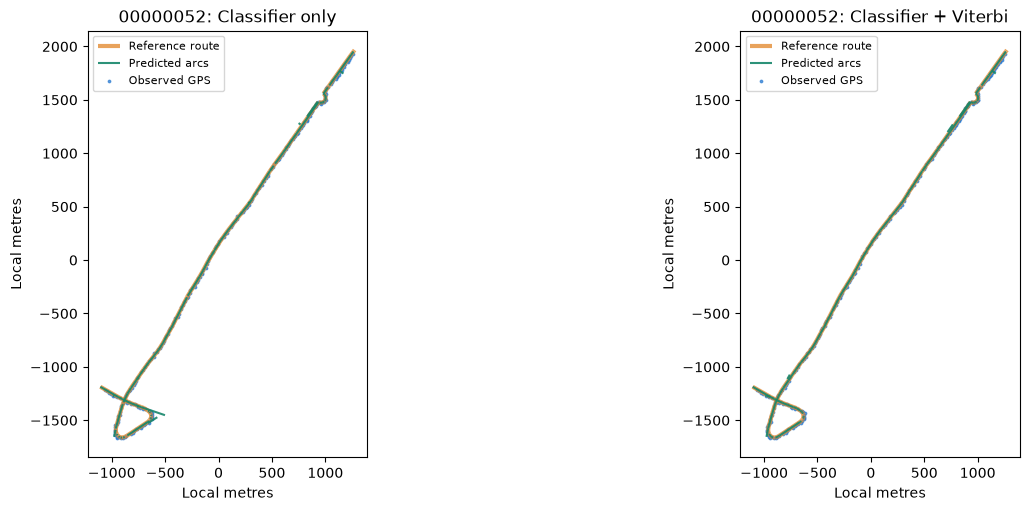

In [4]:
example_id = "00000052"
item, classifier, decoded = decoded_by_trip[example_id]
trip, road, ids = item["trip"], item["road"], item["point_ids"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, chosen, title in zip(axes, [classifier, decoded], ["Classifier only", "Classifier + Viterbi"]):
    ref = np.unique(trip.route)
    ax.add_collection(LineCollection(np.stack([road.a[ref], road.b[ref]], axis=1),
        colors="#e38b32", linewidths=3, alpha=.8, label="Reference route"))
    selected = np.unique(chosen)
    ax.add_collection(LineCollection(np.stack([road.a[selected], road.b[selected]], axis=1),
        colors="#16866b", linewidths=1.5, alpha=.9, label="Predicted arcs"))
    ax.scatter(road.track_xy[ids,0], road.track_xy[ids,1], s=3, color="#2779d1",
        alpha=.7, label="Observed GPS")
    ax.autoscale(); ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{example_id}: {title}"); ax.set_xlabel("Local metres"); ax.set_ylabel("Local metres")
    ax.legend(fontsize=8)
plt.show()

## Viva answers and boundaries

1. **Hidden states?** Six candidate directed road arcs at each GPS observation. Their count changes by observation, but the candidate array has six positions per point. There are no neural hidden layers.
2. **Emissions?** HGB positive-class predict_proba for each candidate, clipped then logged. The inputs are the six engineered features. These probabilities are not a fitted GPS-error density.
3. **Transitions?** Fixed, unnormalized penalties: 0 same arc; 0.25 directed node connection; otherwise 1.5 plus endpoint distance divided by 25 times elapsed seconds. transition_weight defaults to 1.0.
4. **Large gaps or missing candidates?** Elapsed time softens the disconnected penalty. The decoder may jump if necessary. A missing true arc cannot be recovered at that point; bridge_route may insert a plausible directed path afterward.
5. **Disconnected segments?** They receive a larger penalty, not a hard ban. A* bridging is attempted after Viterbi; unresolved links remain visible in the results.
6. **Did decoding help?** Quote both proxy pointwise accuracy and route continuity from the executed per-trip and full-trip tables. Distinguish the 250-point sampled comparison from the full-trip API rehearsal. Do not claim that smoother always means more correct.
7. **Is this a fully trained HMM?** No. Emissions come from a discriminative classifier, transition terms are hand-set scores, and no normalized initial/transition distributions are learned. Call it HMM-style Viterbi map matching.
8. **How could it fail?** Wrong candidate generation, noisy/un-calibrated emissions, disconnected road graphs, unusually long GPS gaps, or a transition penalty that prefers a smooth wrong road. The full student-test rehearsal still has unresolved links.